In [ ]:
# LSTM for international airline passengers problem with regression framing
import numpy as np
import matplotlib.pyplot as plt
from pandas import read_csv
import math
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error


# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)
# fix random seed for reproducibility
tf.random.set_seed(7)
# load the dataset
dataframe = read_csv('../preprocess/parking_time_series_with_features_15min.csv', usecols=[1], engine='python')
dataset = dataframe.values
dataset = dataset.astype('float32')

In [ ]:

# Normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# Split into train and test sets
train_size = int(len(dataset) * 0.80)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]

# reshape into X=t and Y=t+1

look_back = 1
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

# Reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

# create and fit the LSTM network
model = Sequential()
model.add(LSTM(4, input_shape=(1, look_back)))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam')
history = model.fit(trainX, trainY, epochs=100, batch_size=1, verbose=2)

Epoch 1/100


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7371/7371 - 3s - 363us/step - loss: 0.0105
Epoch 2/100
7371/7371 - 2s - 296us/step - loss: 0.0013
Epoch 3/100
7371/7371 - 2s - 294us/step - loss: 0.0013
Epoch 4/100
7371/7371 - 2s - 301us/step - loss: 0.0013
Epoch 5/100
7371/7371 - 2s - 308us/step - loss: 0.0013
Epoch 6/100
7371/7371 - 2s - 290us/step - loss: 0.0013
Epoch 7/100
7371/7371 - 2s - 288us/step - loss: 0.0013
Epoch 8/100
7371/7371 - 2s - 294us/step - loss: 0.0013
Epoch 9/100
7371/7371 - 2s - 294us/step - loss: 0.0013
Epoch 10/100
7371/7371 - 2s - 287us/step - loss: 0.0013
Epoch 11/100
7371/7371 - 2s - 289us/step - loss: 0.0013
Epoch 12/100
7371/7371 - 2s - 294us/step - loss: 0.0013
Epoch 13/100
7371/7371 - 2s - 291us/step - loss: 0.0013
Epoch 14/100
7371/7371 - 2s - 291us/step - loss: 0.0013
Epoch 15/100
7371/7371 - 2s - 288us/step - loss: 0.0013
Epoch 16/100
7371/7371 - 2s - 288us/step - loss: 0.0013
Epoch 17/100
7371/7371 - 2s - 287us/step - loss: 0.0013
Epoch 18/100
7371/7371 - 2s - 287us/step - loss: 0.0013
Epoch 19/100


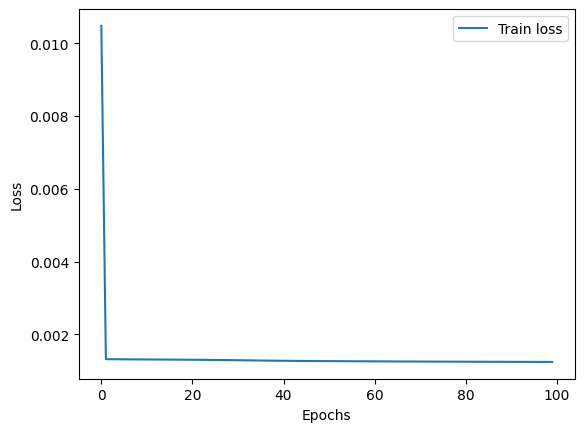

In [ ]:
plt.plot(history.history['loss'], label='Train loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

231/231 ━━━━━━━━━━━━━━━━━━━━ 0s 535us/step
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 245us/step
Train Score: 48.90 RMSE
Test Score: 35.76 RMSE
Train Score: 20.85 MAE
Test Score: 16.12 MAE


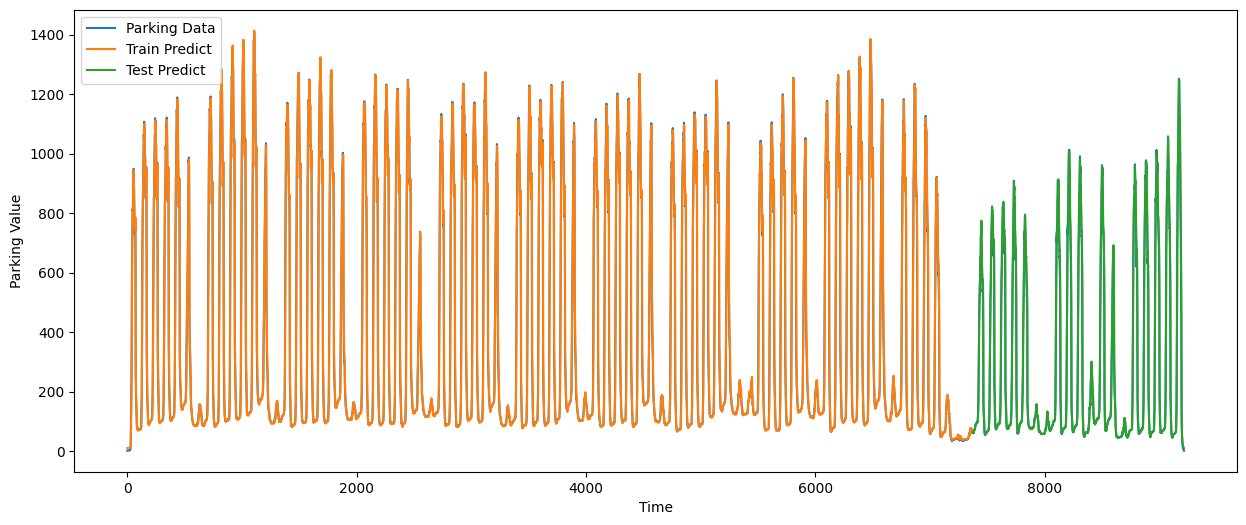

In [ ]:

# Predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

# Invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# Calculate RMSE
trainScore = np.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

# Calculate MAE
trainScoreMAE = mean_absolute_error(trainY[0], trainPredict[:,0])
print('Train Score: %.2f MAE' % (trainScoreMAE))
testScoreMAE = mean_absolute_error(testY[0], testPredict[:,0])
print('Test Score: %.2f MAE' % (testScoreMAE))

# Shift predictions for plotting
trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict

# Plotting
plt.figure(figsize=(15, 6))
plt.plot(scaler.inverse_transform(dataset), label='Parking Data')
plt.plot(trainPredictPlot, label='Train Predict')
plt.plot(testPredictPlot, label='Test Predict')
plt.xlabel('Time')
plt.ylabel('Parking Value')
plt.legend()
plt.show()